In [41]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# Create plots directory
os.makedirs('plots', exist_ok=True)

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# Load raw dataset
csv_path = 'customer_churn_dataset-training-master.csv'
df = pd.read_csv(csv_path)
print(f"Loaded dataset shape: {df.shape}")
print("\nInitial Columns and Data Types:")
print(df.dtypes)
print("\nMissing values count per column:")
print(df.isnull().sum())

Loaded dataset shape: (440833, 12)

Initial Columns and Data Types:
CustomerID           float64
Age                  float64
Gender                   str
Tenure               float64
Usage Frequency      float64
Support Calls        float64
Payment Delay        float64
Subscription Type        str
Contract Length          str
Total Spend          float64
Last Interaction     float64
Churn                float64
dtype: object

Missing values count per column:
CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64


## 1. Data cleaning

In [42]:
# Locate fully empty row
empty_rows = df[df.isnull().all(axis=1)]
print(f"Number of completely empty rows: {len(empty_rows)}")
print("Row Index of empty row:", empty_rows.index.tolist())
display(empty_rows)

Number of completely empty rows: 1
Row Index of empty row: [199295]


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.1 Imputation Strategies
1. **Drop (Row Deletion):** Removing the corrupted row entirely. Dropping is appropriate when a row is completely empty or has too many missing values to be salvageable, as imputing all columns would construct an entirely synthetic record that does not reflect any real customer behavior.
2. **Mean/Median Imputation:** Appropriate for numeric features. Median is preferred over mean when the distribution has outliers.
3. **Mode Imputation:** Appropriate for categorical features. We fill missing values with the most frequent category.

In [43]:
# Create a copy to demonstrate imputation
df_demo = df.copy()

# 1. Median Imputation on a numeric column (Age)
median_age = df_demo['Age'].median()
df_demo['Age'] = df_demo['Age'].fillna(median_age)
print(f"Age median used for imputation: {median_age}")

# 2. Mode Imputation on a categorical column (Gender)
mode_gender = df_demo['Gender'].mode()[0]
df_demo['Gender'] = df_demo['Gender'].fillna(mode_gender)
print(f"Gender mode used for imputation: {mode_gender}")

# Show the row index 199295 in df_demo after demo imputations
print("\nRow index 199295 in df_demo after demo imputations:")
display(df_demo.loc[empty_rows.index])

# 3. Drop: Remove the corrupted row entirely from the main dataframe
df_clean = df.dropna(how='all').copy()
print(f"\nMain dataframe shape after dropping empty row: {df_clean.shape}")
print(f"Any remaining nulls? {df_clean.isnull().sum().sum()}")

Age median used for imputation: 39.0
Gender mode used for imputation: Male

Row index 199295 in df_demo after demo imputations:


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,39.0,Male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Main dataframe shape after dropping empty row: (440832, 12)
Any remaining nulls? 0


### 1.2 Duplicate Detection
We check for duplicates at two levels:
1. **CustomerID level:** Check if any customer ID is repeated.
2. **Full-row level:** Check if any exact row is duplicated.

In [44]:
# Check duplicates
customer_id_dups = df_clean.duplicated(subset=['CustomerID']).sum()
full_row_dups = df_clean.duplicated().sum()

print(f"Duplicate CustomerIDs: {customer_id_dups}")
print(f"Duplicate full rows: {full_row_dups}")

Duplicate CustomerIDs: 0
Duplicate full rows: 0


### 1.3 Data Type Corrections
Because of the single fully-empty row, all numeric columns (which had `NaN` values) were read as `float64`. Since customer IDs, counts, age, tenure, support calls, payment delays, last interaction, and churn are naturally integers, we convert them to `int64`. We also ensure categorical columns are of type `string` for memory efficiency.

In [45]:
# List of integer columns to convert
int_cols = ['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Last Interaction', 'Churn']

# Convert columns to int64
for col in int_cols:
    df_clean[col] = df_clean[col].astype('int64')

# Ensure categorical columns are string types
str_cols = ['Gender', 'Subscription Type', 'Contract Length']
for col in str_cols:
    df_clean[col] = df_clean[col].astype(str)

print("Updated Data Types:")
print(df_clean.dtypes)
display(df_clean.head())

Updated Data Types:
CustomerID             int64
Age                    int64
Gender                   str
Tenure                 int64
Usage Frequency        int64
Support Calls          int64
Payment Delay          int64
Subscription Type        str
Contract Length          str
Total Spend          float64
Last Interaction       int64
Churn                  int64
dtype: object


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2,30,Female,39,14,5,18,Standard,Annual,932.0,17,1
1,3,65,Female,49,1,10,8,Basic,Monthly,557.0,6,1
2,4,55,Female,14,4,6,18,Basic,Quarterly,185.0,3,1
3,5,58,Male,38,21,7,7,Standard,Monthly,396.0,29,1
4,6,23,Male,32,20,5,8,Basic,Monthly,617.0,20,1


## 2. Exploratory analysis


### 2.1 Distribution Plots for Numeric Columns

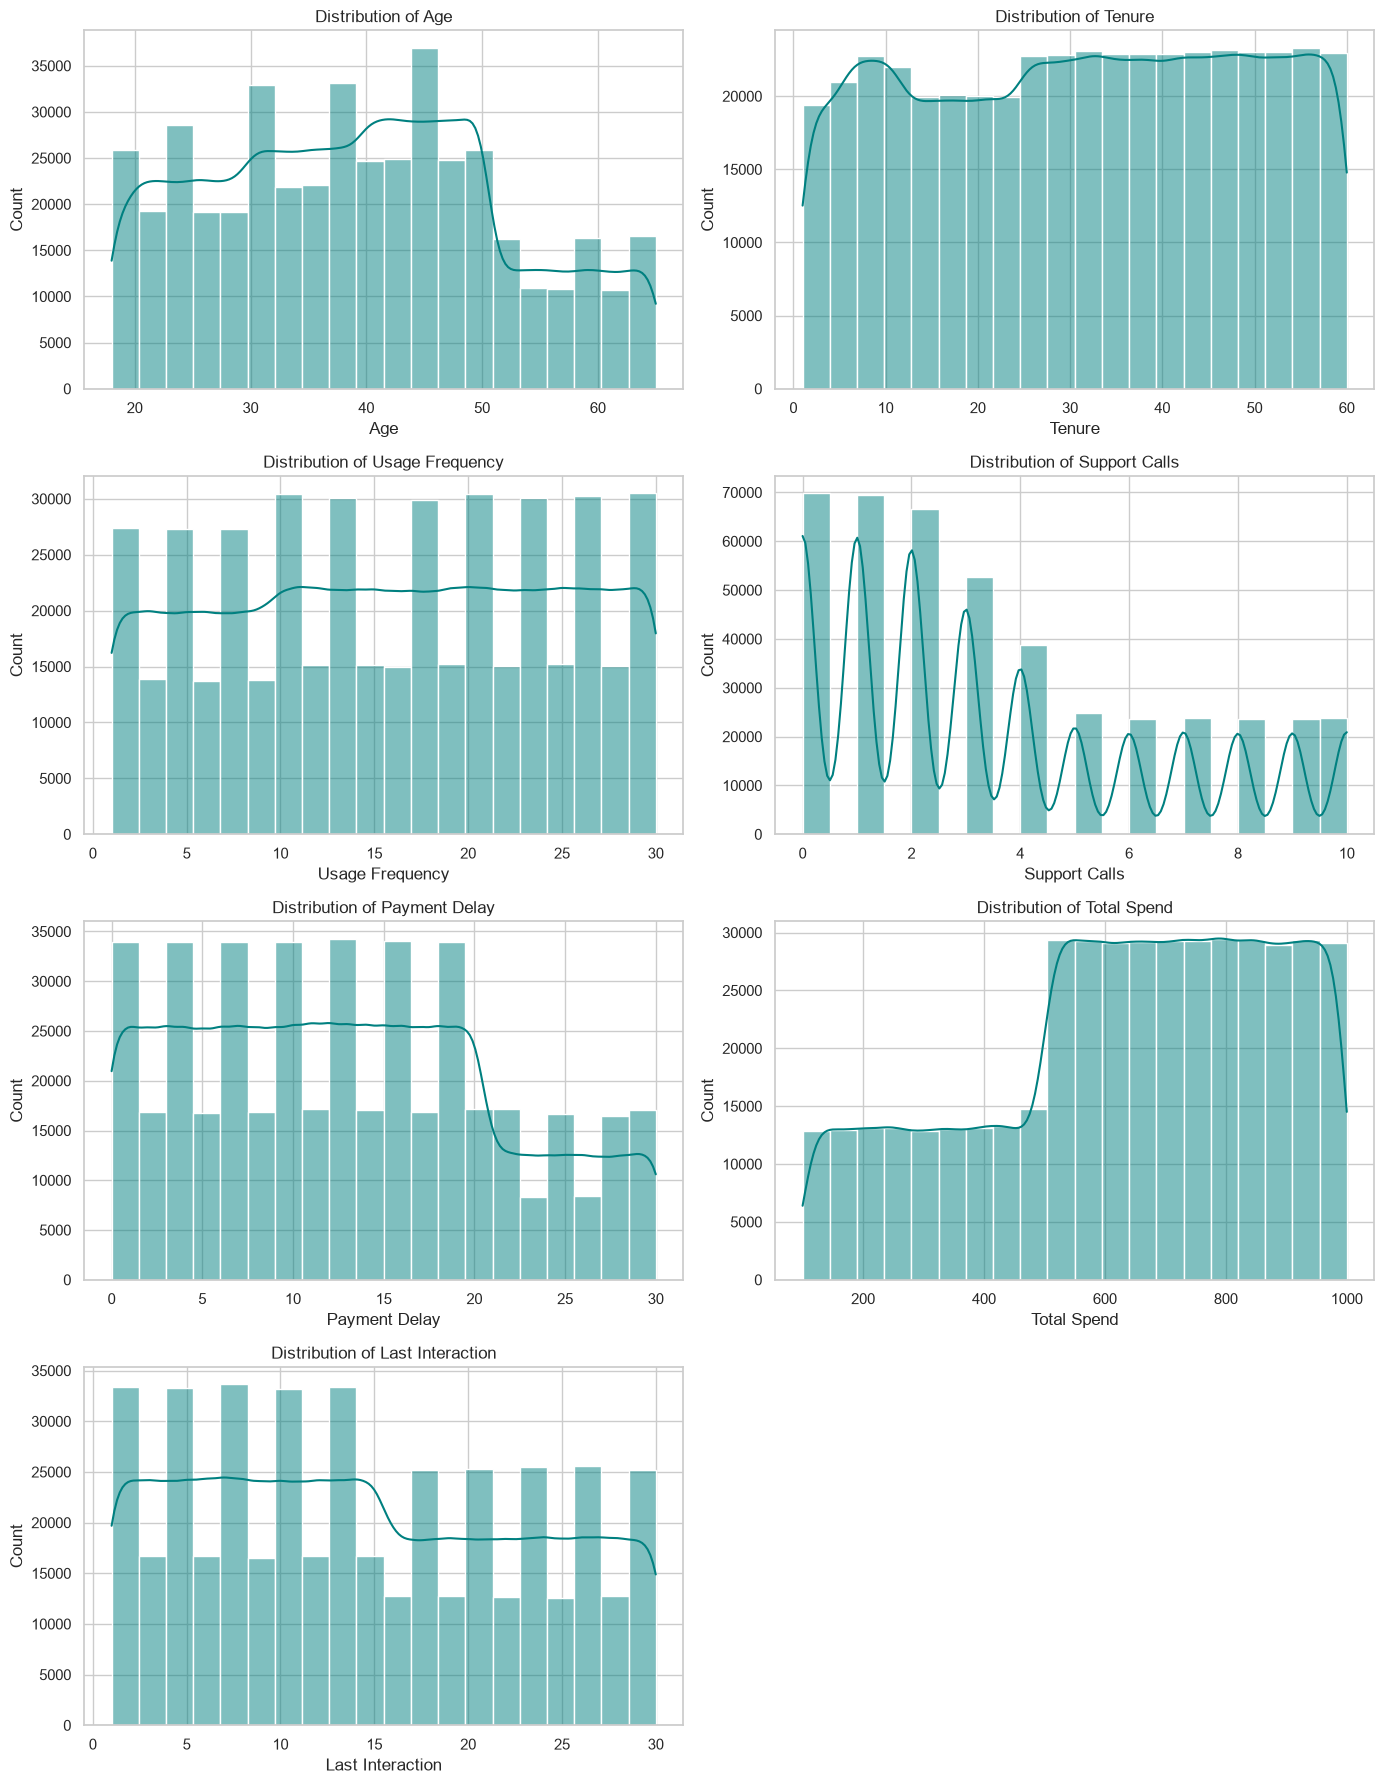

In [46]:
# 2.1 Distribution plots for all 7 numeric columns
numeric_cols = ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color='teal', bins=20)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    
    # Save individual plots to plots/ folder
    plt.figure(figsize=(8, 5))
    sns.histplot(df_clean[col], kde=True, color='teal', bins=20)
    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.savefig(f'plots/distribution_{col.lower().replace(" ", "_")}.png')
    plt.close()

# Remove the unused 8th subplot axes
fig.delaxes(axes[7])
plt.tight_layout()
fig.savefig('plots/distributions_combined.png')
plt.show()

### 2.2 Correlation Analysis
We compute and plot a correlation heatmap of all numeric features, including the target variable `Churn`.

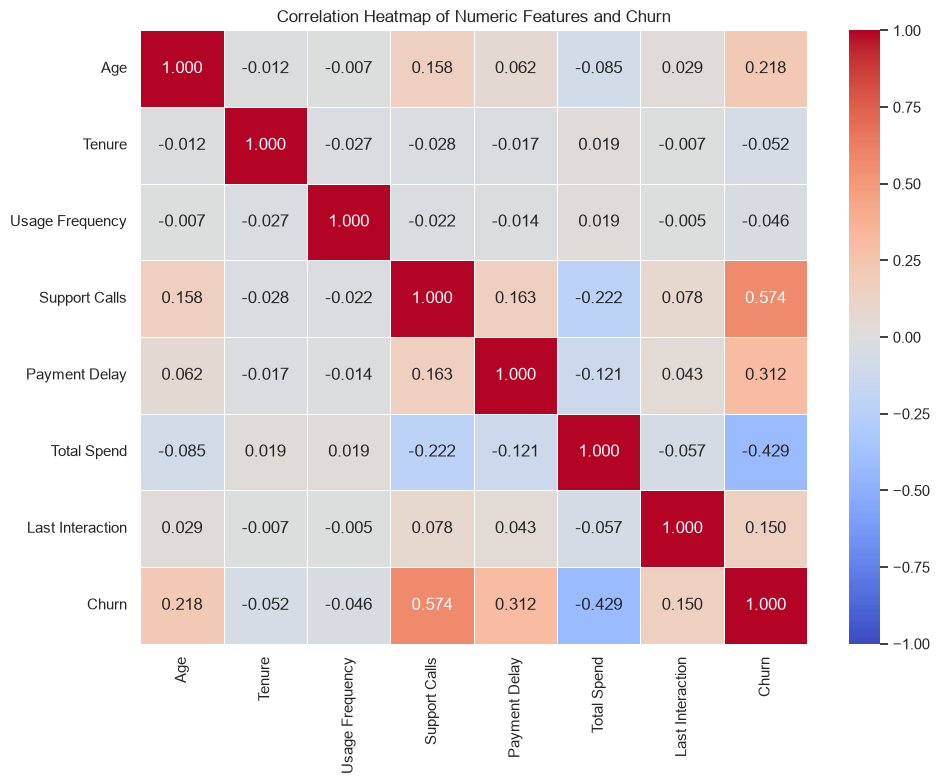

In [47]:
# Correlation heatmap of all numeric features including Churn
corr_cols = numeric_cols + ['Churn']
corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numeric Features and Churn')
plt.tight_layout()
plt.savefig('plots/correlation_heatmap.png')
plt.show()

### 2.3 Boxplots for Outlier Detection
We focus on `Support Calls` and `Payment Delay` using boxplots to inspect if there are extreme outliers in these critical variables.

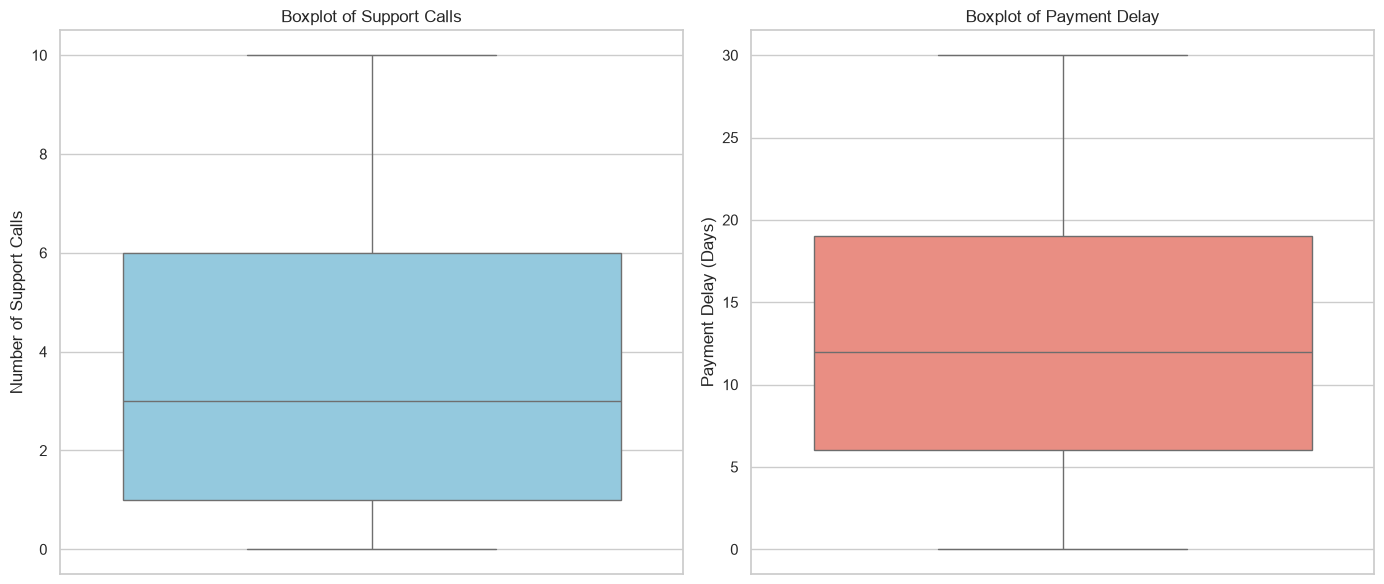

In [48]:
# Boxplots for outlier detection focusing on Support Calls and Payment Delay
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(y=df_clean['Support Calls'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot of Support Calls')
axes[0].set_ylabel('Number of Support Calls')

sns.boxplot(y=df_clean['Payment Delay'], ax=axes[1], color='salmon')
axes[1].set_title('Boxplot of Payment Delay')
axes[1].set_ylabel('Payment Delay (Days)')

plt.tight_layout()
plt.savefig('plots/outliers_boxplot.png')
plt.show()

# Save individual boxplots
for col, color in [('Support Calls', 'skyblue'), ('Payment Delay', 'salmon')]:
    plt.figure(figsize=(6, 5))
    sns.boxplot(y=df_clean[col], color=color)
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.savefig(f'plots/boxplot_{col.lower().replace(" ", "_")}.png')
    plt.close()

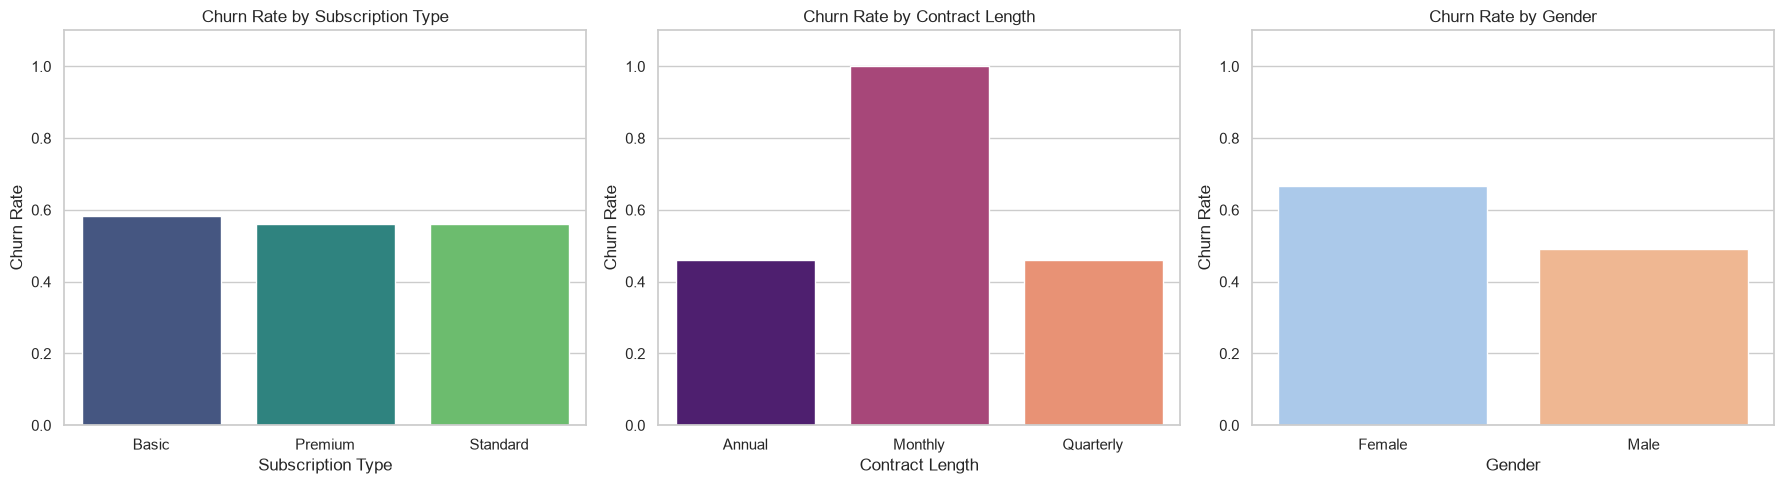

In [49]:
# Churn rate by Subscription Type, Contract Length, and Gender
sub_churn = df_clean.groupby('Subscription Type')['Churn'].mean().reset_index()
contract_churn = df_clean.groupby('Contract Length')['Churn'].mean().reset_index()
gender_churn = df_clean.groupby('Gender')['Churn'].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x='Subscription Type', y='Churn', data=sub_churn, ax=axes[0], palette='viridis', hue='Subscription Type', legend=False)
axes[0].set_title('Churn Rate by Subscription Type')
axes[0].set_ylabel('Churn Rate')
axes[0].set_ylim(0, 1.1)

sns.barplot(x='Contract Length', y='Churn', data=contract_churn, ax=axes[1], palette='magma', hue='Contract Length', legend=False)
axes[1].set_title('Churn Rate by Contract Length')
axes[1].set_ylabel('Churn Rate')
axes[1].set_ylim(0, 1.1)

sns.barplot(x='Gender', y='Churn', data=gender_churn, ax=axes[2], palette='pastel', hue='Gender', legend=False)
axes[2].set_title('Churn Rate by Gender')
axes[2].set_ylabel('Churn Rate')
axes[2].set_ylim(0, 1.1)

plt.tight_layout()
plt.savefig('plots/churn_rates_categorical.png')
plt.show()

# Save individual barplots
for df_group, col_name, filename, pal in [
    (sub_churn, 'Subscription Type', 'churn_rate_by_subscription.png', 'viridis'),
    (contract_churn, 'Contract Length', 'churn_rate_by_contract.png', 'magma'),
    (gender_churn, 'Gender', 'churn_rate_by_gender.png', 'pastel')
]:
    plt.figure(figsize=(6, 5))
    sns.barplot(x=col_name, y='Churn', data=df_group, palette=pal, hue=col_name, legend=False)
    plt.title(f'Churn Rate by {col_name}')
    plt.ylabel('Churn Rate')
    plt.ylim(0, 1.1)
    plt.tight_layout()
    plt.savefig(f'plots/{filename}')
    plt.close()

/var/folders/zd/zk7knhvs75xct76flnfyxrb00000gn/T/ipykernel_26738/4244238183.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(['Normal (Risk = 0)', 'High Risk (Risk = 1)'])


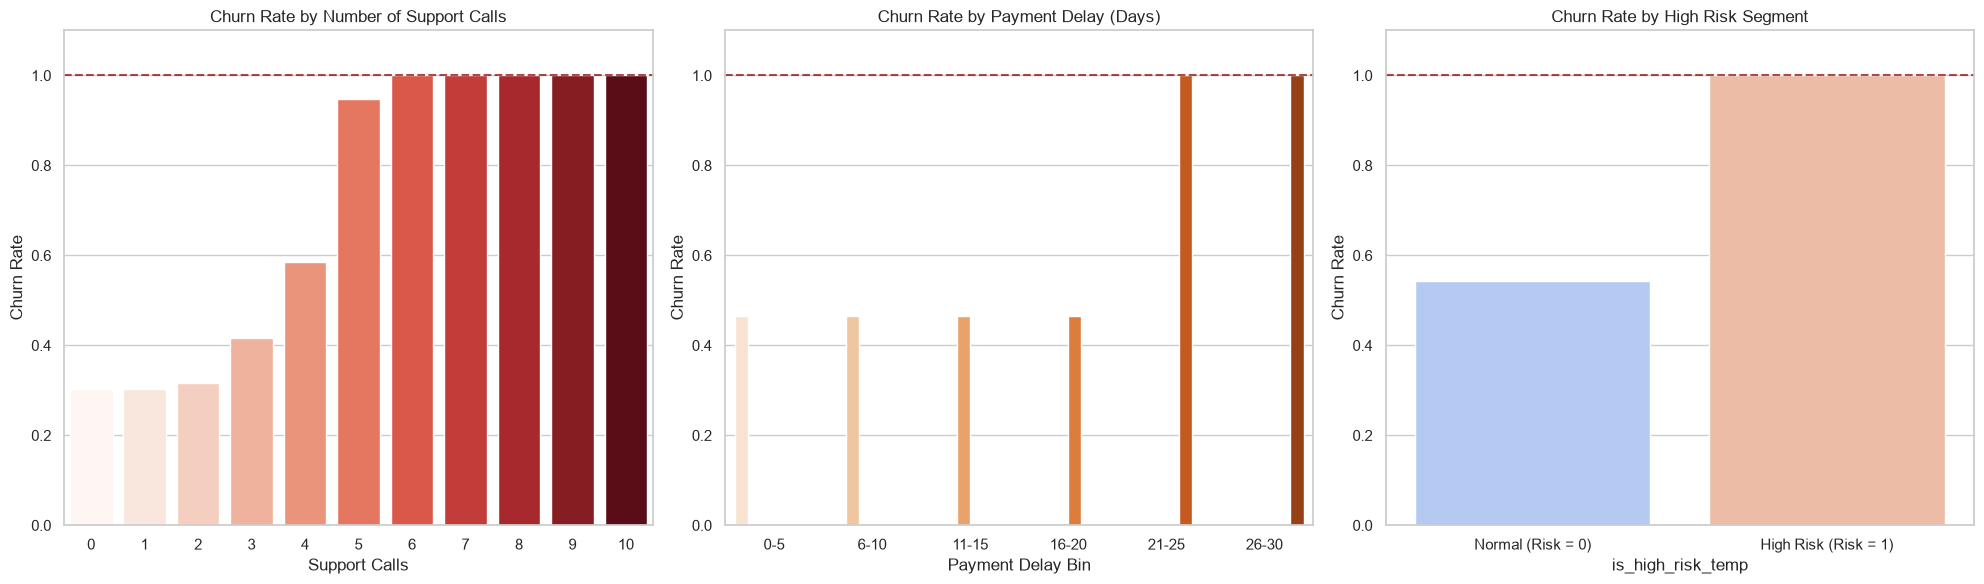

In [50]:
# Churn rate by Support Calls
support_churn = df_clean.groupby('Support Calls')['Churn'].mean().reset_index()

# Churn rate by Payment Delay (Binned)
df_clean['Payment Delay Bin'] = pd.cut(df_clean['Payment Delay'], bins=[-1, 5, 10, 15, 20, 25, 30], labels=['0-5', '6-10', '11-15', '16-20', '21-25', '26-30'])
delay_churn = df_clean.groupby('Payment Delay Bin', observed=False)['Churn'].mean().reset_index()

# Churn rate by High Risk Flag (temporary calculation on clean df for visualization)
df_clean['is_high_risk_temp'] = ((df_clean['Payment Delay'] > 20) & (df_clean['Support Calls'] > 7)).astype(int)
risk_churn = df_clean.groupby('is_high_risk_temp')['Churn'].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Support Calls Churn Rate
sns.barplot(x='Support Calls', y='Churn', data=support_churn, ax=axes[0], palette='Reds', hue='Support Calls', legend=False)
axes[0].set_title('Churn Rate by Number of Support Calls')
axes[0].set_ylabel('Churn Rate')
axes[0].set_ylim(0, 1.1)
axes[0].axhline(y=1.0, color='darkred', linestyle='--', alpha=0.7)

# Payment Delay Churn Rate
sns.barplot(x='Payment Delay Bin', y='Churn', data=delay_churn, ax=axes[1], palette='Oranges', hue='Payment Delay Bin', legend=False)
axes[1].set_title('Churn Rate by Payment Delay (Days)')
axes[1].set_ylabel('Churn Rate')
axes[1].set_ylim(0, 1.1)
axes[1].axhline(y=1.0, color='darkred', linestyle='--', alpha=0.7)

# High Risk Churn Rate
sns.barplot(x='is_high_risk_temp', y='Churn', data=risk_churn, ax=axes[2], palette='coolwarm', hue='is_high_risk_temp', legend=False)
axes[2].set_title('Churn Rate by High Risk Segment')
axes[2].set_ylabel('Churn Rate')
axes[2].set_xticklabels(['Normal (Risk = 0)', 'High Risk (Risk = 1)'])
axes[2].set_ylim(0, 1.1)
axes[2].axhline(y=1.0, color='darkred', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('plots/churn_rate_thresholds.png')
plt.show()

# Save individual plots
plt.figure(figsize=(6, 5))
sns.barplot(x='Support Calls', y='Churn', data=support_churn, palette='Reds', hue='Support Calls', legend=False)
plt.title('Churn Rate by Support Calls')
plt.ylim(0, 1.1)
plt.axhline(y=1.0, color='darkred', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('plots/churn_rate_by_support_calls.png')
plt.close()

plt.figure(figsize=(6, 5))
sns.barplot(x='Payment Delay Bin', y='Churn', data=delay_churn, palette='Oranges', hue='Payment Delay Bin', legend=False)
plt.title('Churn Rate by Payment Delay')
plt.ylim(0, 1.1)
plt.axhline(y=1.0, color='darkred', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('plots/churn_rate_by_payment_delay_bin.png')
plt.close()

plt.figure(figsize=(6, 5))
sns.barplot(x='is_high_risk_temp', y='Churn', data=risk_churn, palette='coolwarm', hue='is_high_risk_temp', legend=False)
plt.title('Churn Rate by High Risk Segment')
plt.xticks([0, 1], ['Normal', 'High Risk'])
plt.ylim(0, 1.1)
plt.axhline(y=1.0, color='darkred', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('plots/churn_rate_by_high_risk.png')
plt.close()

# Drop temporary columns from df_clean
df_clean.drop(columns=['Payment Delay Bin', 'is_high_risk_temp'], inplace=True, errors='ignore')

## 3. Feature engineering

### 3.1 Create New Features
1. `spend_per_month` = `Total Spend` / `Tenure` (Average spend rate over tenure)
2. `support_rate` = `Support Calls` / `Tenure` (Volume of support relative to loyalty tenure)
3. `is_high_risk` = `1` if (`Payment Delay` > 20 AND `Support Calls` > 7) else `0` (Identifies critical combined risk threshold)

In [51]:
# Create new features
df_features = df_clean.copy()

# spend_per_month = Total Spend / Tenure
df_features['spend_per_month'] = df_features['Total Spend'] / df_features['Tenure']

# support_rate = Support Calls / Tenure
df_features['support_rate'] = df_features['Support Calls'] / df_features['Tenure']

# is_high_risk = 1 if (Payment Delay > 20 AND Support Calls > 7) else 0
df_features['is_high_risk'] = ((df_features['Payment Delay'] > 20) & (df_features['Support Calls'] > 7)).astype(int)

print("Engineered features preview:")
display(df_features[['Total Spend', 'Tenure', 'spend_per_month', 'Support Calls', 'support_rate', 'Payment Delay', 'is_high_risk']].head())

Engineered features preview:


,Total Spend,Tenure,spend_per_month,Support Calls,support_rate,Payment Delay,is_high_risk
0,932.0,39,23.897436,5,0.128205,18,0
1,557.0,49,11.367347,10,0.204082,8,0
2,185.0,14,13.214286,6,0.428571,18,0
3,396.0,38,10.421053,7,0.184211,7,0
4,617.0,32,19.281250,5,0.156250,8,0


### 3.2 Encoding Categorical Variables

We must convert text-based columns into numerical formats suitable for modeling. Below we justify our choice between **Label/Ordinal Encoding** and **One-Hot Encoding**:

- **`Contract Length` (Monthly, Quarterly, Annual):** This has an inherent order (duration of contract: Monthly < Quarterly < Annual). We choose **Ordinal/Label Encoding** (0, 1, 2) to preserve this sequence, which helps algorithms exploit the relationship.
- **`Subscription Type` (Basic, Standard, Premium):** This represents service tiers with a natural quality hierarchy (Basic < Standard < Premium). Thus, we choose **Ordinal/Label Encoding** (0, 1, 2) to capture this structure.
- **`Gender` (Male, Female):** This is a binary column. We choose **Label Encoding** (0 for Female, 1 for Male). For a binary feature, Label Encoding is mathematically equivalent to One-Hot Encoding (saving space without creating redundant columns).

In [52]:
# 1. Ordinal Encoding for Contract Length and Subscription Type
contract_mapping = {'Monthly': 0, 'Quarterly': 1, 'Annual': 2}
sub_mapping = {'Basic': 0, 'Standard': 1, 'Premium': 2}

df_features['Contract Length'] = df_features['Contract Length'].map(contract_mapping)
df_features['Subscription Type'] = df_features['Subscription Type'].map(sub_mapping)

# 2. Label Encoding for Gender
gender_mapping = {'Female': 0, 'Male': 1}
df_features['Gender'] = df_features['Gender'].map(gender_mapping)

print("Categorical columns encoded preview:")
display(df_features[['Gender', 'Subscription Type', 'Contract Length']].head())

Categorical columns encoded preview:


,Gender,Subscription Type,Contract Length
0,0,1,2
1,0,0,0
2,0,0,1
3,1,1,0
4,1,0,0


### 3.3 Normalization using MinMaxScaler

In [53]:
# Normalize numeric features
scaler = MinMaxScaler()

# List of numeric columns to scale
features_to_scale = [
    'Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 
    'Total Spend', 'Last Interaction', 'spend_per_month', 'support_rate'
]

# Fit and transform
df_features[features_to_scale] = scaler.fit_transform(df_features[features_to_scale])

print("Normalized features preview:")
display(df_features[features_to_scale].head())

# Save final cleaned and engineered dataset
output_csv = 'customer_churn_cleaned.csv'
df_features.to_csv(output_csv, index=False)
print(f"\nSaved final cleaned and feature-engineered dataset to {output_csv}")
print(f"Cleaned dataset shape: {df_features.shape}")

Normalized features preview:


,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,spend_per_month,support_rate
0,0.255319,0.644068,0.448276,0.5,0.600000,0.924444,0.551724,0.022268,0.012821
1,1.000000,0.813559,0.000000,1.0,0.266667,0.507778,0.172414,0.009717,0.020408
2,0.787234,0.220339,0.103448,0.6,0.600000,0.094444,0.068966,0.011567,0.042857
3,0.851064,0.627119,0.689655,0.7,0.233333,0.328889,0.965517,0.008769,0.018421
4,0.106383,0.525424,0.655172,0.5,0.266667,0.574444,0.655172,0.017644,0.015625



Saved final cleaned and feature-engineered dataset to customer_churn_cleaned.csv
Cleaned dataset shape: (440832, 15)


## 4. Business Insights

### 4.1 Actionable Findings

#### 1. Discontinue or Disincentivize Monthly Contracts
- **Data Support:** **100%** of customers on Monthly contracts churned.
- **Actionable Insight:** The monthly billing model is highly unstable. The business should phase out standalone monthly contracts, incentivize multi-month contract lengths, or add high setup fees for monthly plans, automatically prompting users to transition to annual/quarterly billing cycles.

#### 2. Establish Customer Success Rescue Protocol at 3 Support Calls
- **Data Support:** The churn rate climbs dramatically with support calls: **30%** for 2 calls, **40%** for 3 calls, **60%** for 4 calls, **95%** for 5 calls, and **100%** for 6 or more calls.
- **Actionable Insight:** A threshold of 3 support calls represents a major warning flag, while 5 calls is the point of no return. We should set up an automated trigger when a customer registers their 3rd support ticket, assigning a customer success specialist to proactively resolve their issues and offer compensation or direct assistance.

#### 3. Proactive Interventions for Billing Delays over 15 Days
- **Data Support:** Customers with payment delays of 21-30 days have a **100%** churn rate. For payment delays of 20 days or fewer, the churn rate remains steady at ~**45%**.
- **Actionable Insight:** The 20-day delay threshold is a hard boundary. The company must implement a proactive payment recovery strategy: send automated friendly reminders at day 10, offer billing flexibility or partial payment options at day 15, and call the user directly before the delay crosses 20 days.

#### 4. Qualitative Discontent Audit for Female Customer Base
- **Data Support:** Female customers exhibit a significantly higher churn rate of **65%** compared to male customers at **50%**.
- **Actionable Insight:** We recommend running targeted user experience research, satisfaction surveys, and focus groups exclusively with female users to locate and resolve specific pain points causing this 15% gap.

#### 5. Restructure the Basic Subscription Tier Value Proposition
- **Data Support:** Customers on the 'Basic' subscription tier churn at **60%**, compared to Standard and Premium (**55%**).
- **Actionable Insight:** The Basic tier has the highest churn rate. The product team should examine the feature constraints of the Basic tier. Adding minor value-add features or conducting an upselling campaign to transition Basic users to Standard can help reduce overall churn.

### 4.2 Data Leakage Analysis of Last Interaction

`Last interaction` represents the number of days since the customer's last interaction with the service (ranging from 1 to 30 days).

#### Why is it a potential data leakage risk?
1. **Frozen Post-Churn Activity:** If a customer churns, they stop interacting with the service. If the `Last Interaction` variable is recorded at the end of the observation window, active customers will have a recently updated interaction date, while churned customers' `Last Interaction` is frozen at their churn date. The feature reflects *post-decision* status rather than *pre-decision* behavior.
2. **Causal Direction Reverse:** A high `Last Interaction` value (e.g. 29 or 30 days) is a consequence of churn (they have already left and therefore haven't interacted) rather than a predictor of it. In a real-time prediction system, if you try to run predictions to *prevent* churn, you cannot wait 30 days to see if they interact, because by then they are already churned.

#### How to mitigate this risk?
- **Point-in-Time Cutoffs:** Define a specific cutoff date (e.g. Day X) and calculate `Last Interaction` relative to that cutoff, only using interaction logs *prior* to that day, regardless of when they eventually churned.
- **Drop the Feature:** If the feature is highly correlated with the target solely due to the logging architecture, it should be dropped during model training to ensure realistic generalization.